# D1 Fundamentals and dimensional analysis

## Introduction

The main characteristics of turbomachinery has been already introduced in previous courses of the Batchelor Degree and Master. In this course we explore in 
detail the design of a specific type on hydraulic turbomachine: **the axial fan**

In this first notebook we go over some basic concepts already covered in previous subjects.

## Learning objectives
1. Define the concept of _Hydraulic Turbomachine_
2. Enumerate different kinds of hydraulic turbomachines with the main characteristics
3. Explain the concept of absolute and relative velocities and angles
4. Relate _stagnation_ (or _total_) _enthalpy_ to energy transfer
5. Apply the moment of momentum balance to get the **Euler equation**
6. Define _rothalpy_
7. Define **efficiency** for an axial fan
8. Define **flow and head coefficient**
9. Define specific **speed and specific diameter**
10. Classify turbomachines in function of the **dimensionless parameters**
11. Use the **Cordier diagram** to locate the operation point of a turbomachine

## Previous tasks (about 2.5 hours)

Read part of chapters 1 and 2 of the book by Dixon


  DIXON, S.L. (Sydney L. y HALL, C.A., 2010. Fluid Mechanics and Thermodynamics of Turbomachinery (6th Edition). 6th Edition. Oxford: Elsevier. ISBN 1856177939. 

that is [available on the UPC library](https://discovery.upc.edu/permalink/34CSUC_UPC/12g8t5d/cdi_nii_cinii_1970023484961124628)

Don't read the whole chapters. Avoid the parts about compressible flow that will not be used in the present course. Specifically, read the sections:
- 1.1 to 1.8
- 1.10 (the part about hydraulic machines)
- 2.1 to 2.3
- 2.6

## Some simple questions

What is the main difference between a **driven turbomachine** (Power-absorving) and a **driving turbomachine** (Power-Generating)? Give some examples of both types. How is that related to the **Euler Equation**?

Answer

***

A driven (power-absorbing) turbomachine receives shaft power from an external source and transfers it to the fluid, increasing its pressure or head. Examples are pumps, fans and compressors. A driving (power-generating) turbomachine extracts energy from the fluid and delivers shaft power, as in hydraulic (Pelton, Francis, Kaplan), steam and gas turbines.

The Euler equation gives the specific work exchanged as w = u₂c_θ2 − u₁c_θ1 = Δh₀, where u is the blade speed and c_θ the tangential component of the absolute velocity. In a driven machine u·c_θ increases from rotor inlet to outlet, so work is done on the fluid. In a driving machine it decreases, so work is extracted from the fluid.

***

Explain with your words what is the _rothalpy_. Why is that conserved in a rotor?

Answer

***

Rothalpy is the quantity I = h + w²/2 − u²/2 = h₀,rel − u²/2 = h₀ − u·c_θ. In a rotor, for steady adiabatic flow, it is constant along a streamline. In the rotating frame the blades are stationary and do no work, and the centrifugal field is conservative, so h₀,rel − u²/2 cannot change, even with irreversibilities. The stagnation enthalpy h₀ does change, and the change is exactly the work given by the Euler equation, Δh₀ = Δ(u·c_θ).

***

This is an scheme of the triangle of velocities in the outlet of an axial fan

/home/marcal/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


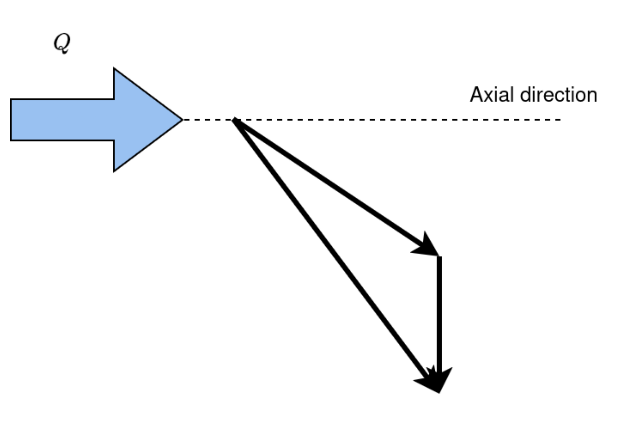

In [1]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# The image
img = mpimg.imread('images/D1_velocities_triangle.png')

# Size of the image
plt.figure(figsize=(8, 6))  # 8 pulgadas de ancho, 6 de alto
plt.imshow(img)
plt.axis('off')  # Without axes
plt.show()

- Locate the **blade velocity** $\mathbf{U}\, (=\mathbf{\omega}\times\mathbf{r})$
- Locate the **absolute velocity** $\mathbf{c}$ and its components $c_\theta$ and $c_x$
- Locate the **relative velocity** $\mathbf{w}$ and its components $w_\theta$ and $w_x$
- Locate **absolute angle** $\alpha$ and **relative angle** $\beta$

Hint: you can use the online app [draw.oi](https://draw.io), copy and paste this diagram, put the answer, export and overwrite the
 `images/D1_velocities_triangle.png` file and run the previous cell. Other option is just draw in by hand or in a tablet and make a picture.

Answer

***

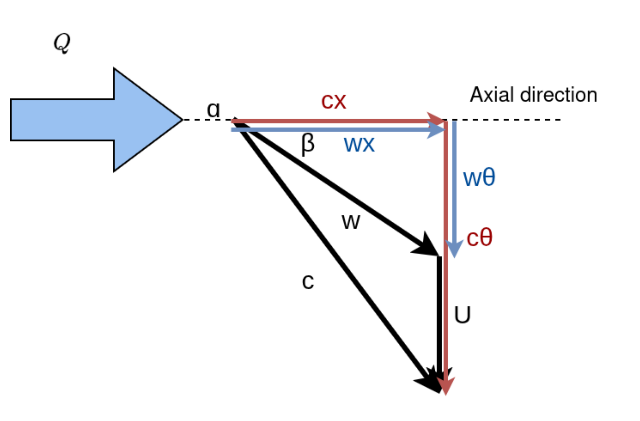

In [2]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# The image
img = mpimg.imread('images/D1_velocity_triangle_work.png')

# Size of the image
plt.figure(figsize=(8, 6))  # 8 pulgadas de ancho, 6 de alto
plt.imshow(img)
plt.axis('off')  # Without axes
plt.show()

## Tasks

These are the main characteristic of the axial fan [TXBR-250 ECOWATT by Soler & Palay](https://www.solerpalau.com/en-en/1634-txbr-ecowatt):

![S&P](images/D1_SP_TXBR-ECOWATT.png)

- Flow rate: $Q = 1617 \; \text{m}^3/\text{h}$
- Rotational speed: $N = 2275 \; \text{rpm}$
- Diameter $D = 250 \; \text{mm}$
- Hub diameter $D_h = 64 \;\text{mm}$
- Consumed power $P = 131\;\text{W}$
- Blade angle in outlet (_trailing edge_): $\beta_2 = 50^\circ$

Questions:

- Compute mean radius. It can be done with average radius, $r_m = \frac{1}{2}\left(r_h + r_t\right)$, or with the RMS, that is more accurate and it will be used later for the 3D analysis, $r_m = \sqrt{\frac{1}{2}\left(r_h^2 + r_t^2\right)}$
- Compute the **blade velocity** $U$
- Compute average **axial velocity** of air in inlet, $c_{x,1}$ and consider it as the axial velocity in the mean radius.
- Inlet flow is axial. Compute the **blade angle in inlet** (_leading edge_) $\beta_1$
- Compute tangential components of **absolute velocity** in the leading and the trailing edges ($c_{\theta1}$ and $c_{\theta2}$)
- Draw the **triangles of velocities** in leading and trailing edges
- Apply **Euler equation** to estimate head pressure of the fan. Express it in Pa, bar and mmH2O
- Estimate the **efficiency** the fan

In [3]:
# TODO: Compute velocities and angles, and draw the triangles of velocities. Apply Euler equation to estimate head pressure. Compute efficiency.
import numpy as np

D_h = 0.064 
D_t = 0.25
r_h = D_h / 2
r_t = D_t / 2
r_rms = (0.5 * (r_h**2 + r_t**2))**0.5  # Root mean square radius
print(f"Root mean square radius: {r_rms:.4f} m")

Root mean square radius: 0.0912 m


In [ ]:
angular_velocity = ((2 * np.pi * 2275) / 60)  # rad/s
blade_u = r_rms * angular_velocity
print(f"Blade velocity (U): {blade_u:.4f} m/s")

Blade velocity (U): 21.7365 m/s


In [ ]:
flow_rate = 1617 / 3600  # m³/s
c_x = flow_rate / (np.pi * (r_t**2 - r_h**2))  # Axial velocity
print(f"Axial velocity (c_x): {c_x:.4f} m/s")

Axial velocity (c_x): 9.7921 m/s


In [14]:
beta1 = np.arctan(blade_u/c_x) 
print(f"Inlet angle (β1): {np.degrees(beta1):.4f} degrees")

Inlet angle (β1): 65.7489 degrees


In [13]:
beta2 = np.radians(50)  # Outlet angle
c_theta1 = 0.0
w_theta2 = -c_x*np.tan(beta2)
c_theta2 = blade_u + w_theta2
print(f"c_theta1 = {c_theta1:.2f} m/s")
print(f"c_theta2 = {c_theta2:.2f} m/s")

c_theta1 = 0.00 m/s
c_theta2 = 10.07 m/s


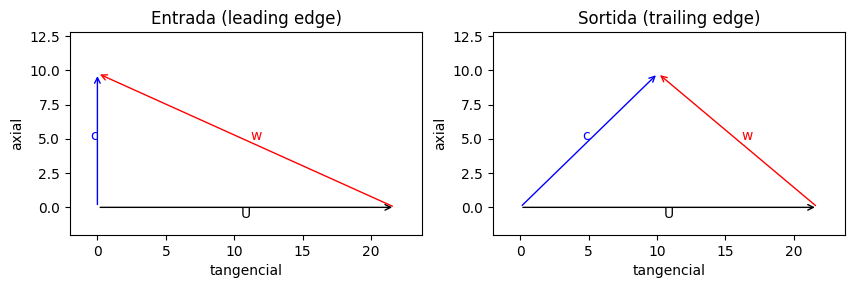

In [15]:
def triangle(ax, U, c_theta, c_x, title):
    # eix x = direcció tangencial, eix y = direcció axial
    ax.annotate("", xy=(U, 0), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="k"))
    ax.annotate("", xy=(c_theta, c_x), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="b"))
    ax.annotate("", xy=(c_theta, c_x), xytext=(U, 0), arrowprops=dict(arrowstyle="->", color="r"))
    ax.text(U/2, -0.8, "U", ha="center")
    ax.text(c_theta/2 - 0.5, c_x/2, "c", color="b")
    ax.text((U + c_theta)/2 + 0.3, c_x/2, "w", color="r")
    ax.set_title(title); ax.set_xlim(-2, U+2); ax.set_ylim(-2, c_x+3)
    ax.set_aspect("equal"); ax.set_xlabel("tangencial"); ax.set_ylabel("axial")

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
triangle(axs[0], blade_u, c_theta1, c_x, "Entrada (leading edge)")
triangle(axs[1], blade_u, c_theta2, c_x, "Sortida (trailing edge)")
plt.show()

In [16]:
w_euler = blade_u*(c_theta2 - c_theta1)
dp = 1.2*w_euler
print(f"Δp = {dp:.1f} Pa = {dp/1e5:.2e} bar = {dp/9.81:.1f} mmH2O")

Δp = 262.6 Pa = 2.63e-03 bar = 26.8 mmH2O


In [17]:
eta = flow_rate*dp/131
print(f"Potència al fluid = {flow_rate*dp:.1f} W, rendiment = {eta:.2f}")

Potència al fluid = 117.9 W, rendiment = 0.90


For the previous fan, compute: 
- flow, head and power coefficients
$$ \phi = \frac{Q}{\omega D^3}$$
$$ \psi = \frac{\Delta p_0}{\rho \omega^2 D^2}$$
$$ \hat{P} = \frac{P_h}{\rho \omega^3 D^5} = \phi \psi$$
- Reynolds number
$$ \text{Re}_D = \frac{\rho c_m D}{\mu} $$
- Specific velocity and diameter
$$ D_s = \frac{D(\frac{\Delta p_0}{\rho})^{1/4}}{Q^{1/2}} $$
$$ \Omega_s = \frac{\Omega Q^{1/2}}{(\frac{\Delta p_0}{\rho})^{3/4}} $$
- Locate the fan into the Cordier diagram 

In [18]:
rho = 1.2                       # kg/m³ (aire, ~20 °C)
mu = 1.8e-5                    # Pa·s (aire, ~20 °C)
dp0 = dp                       # Pa (Euler, ideal)
Ph  = flow_rate*dp0                    # W

phi = flow_rate/(angular_velocity*D_t**3)
psi = dp0/(rho*angular_velocity**2*D_t**2)
P_hat = Ph/(rho*angular_velocity**3*D_t**5)
print(f"phi = {phi:.4f}, psi = {psi:.4f}, P_hat = {P_hat:.5f}, phi*psi = {phi*psi:.5f}")

Re = rho*c_x*D_t/mu
print(f"Re_D = {Re:.3e}")

Ds = D_t*(dp0/rho)**0.25/np.sqrt(flow_rate)
Os = angular_velocity*np.sqrt(flow_rate)/(dp0/rho)**0.75
print(f"Ds = {Ds:.3f}, Omega_s = {Os:.3f}")

phi = 0.1207, psi = 0.0617, P_hat = 0.00744, phi*psi = 0.00744
Re_D = 1.632e+05
Ds = 1.435, Omega_s = 2.806


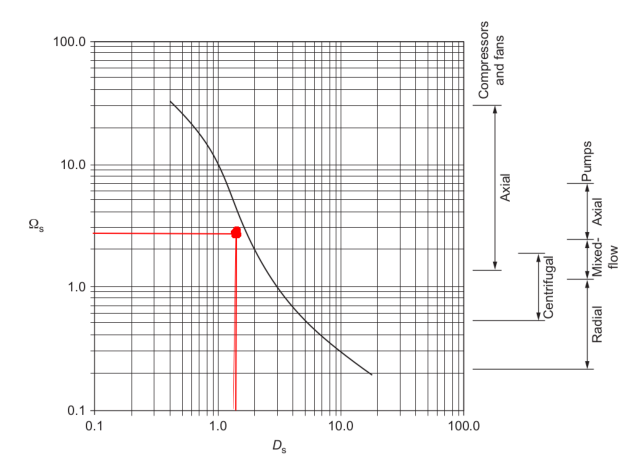

In [19]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# The image
img = mpimg.imread('images/D1_cordier_diagram.png')

# Size of the image
plt.figure(figsize=(8, 6))  # 8 pulgadas de ancho, 6 de alto
plt.imshow(img)
plt.axis('off')  # Without axes
plt.show()

## Your project

Now perform a similar analysis for the axial fan of your project:

- State diameter, rotational speed, flow rate, pressure head, absorbed power
- Estimate mean axial velocity and tangential component of air velocity in the trailing edge according to Euler equation (assume efficiency $\eta = 1$)
- Estimate dimensionless coefficients and locate the fan in the Cordier diagram